# Making Maps from Earth Observation (EO) Imagery

*Section 2 — Making maps, notebook 2 of 4.* Previous: `01_intro_matplotlib.ipynb`. Next: `03_maps_from_vector_data.ipynb`.

**You will learn:**
- how to map a multi-band satellite image with `rsgispy.mapping.raster.create_raster_img_map`;
- how to control the grid, map axes, scale bar and band combination;
- how to add a north arrow, and the north arrow styles;
- how to show several maps side by side, with one scale bar and north arrow, with `rsgispy.mapping.layout.create_map_panels`;
- how the cumulative, standard deviation, linear and user-defined stretches compare;
- how to map a subset of an image and size a figure to fit it with `calc_y_fig_size`.

**Before you start:** the matplotlib basics from `01_intro_matplotlib.ipynb`.

**Data:** `../data/sen2_20210527_aber.tif` (Sentinel-2, Aberystwyth).

**Run time:** less than 1 minute.

This notebook will show how to create maps from raster data layer within continuous pixel values such as satellite imagery.

## Import Modules

In [1]:
%matplotlib inline
import os

import matplotlib.pyplot as plt
import rsgispy
import rsgispy.mapping.layout as map_layout
import rsgispy.mapping.raster

# The figures saved by this notebook are written to the outputs directory
out_dir = "outputs"
os.makedirs(out_dir, exist_ok=True)

## Define the image file path:

In [2]:
input_img = "../data/sen2_20210527_aber.tif"

## Create Simple Map of Satellite Image

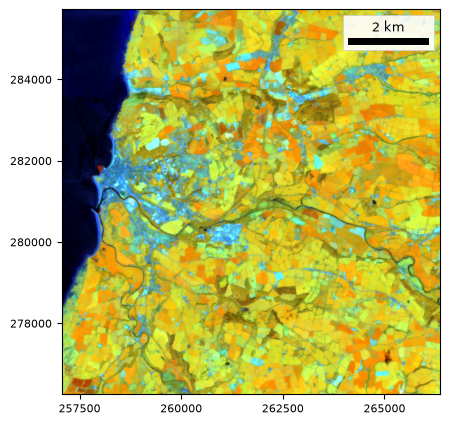

In [3]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

# The function returns the matplotlib image (an AxesImage) it has drawn,
# which can be used, for example, to add a colour bar. Assigning it to a
# variable stops the notebook printing it; below, where we do not need it,
# it is assigned to `_`.
img_artist = rsgispy.mapping.raster.create_raster_img_map(
    ax,  # specify the axis to which the image will be drawn
    input_img,  # specify the file path to the image
    img_bands=[8, 9, 3],  # specify the band combination
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,  # specify the stretch to use
)

## Adding a Grid

Sometime you may want to put a grid over the map, this can be done using the following option. By default the grid is not shown.

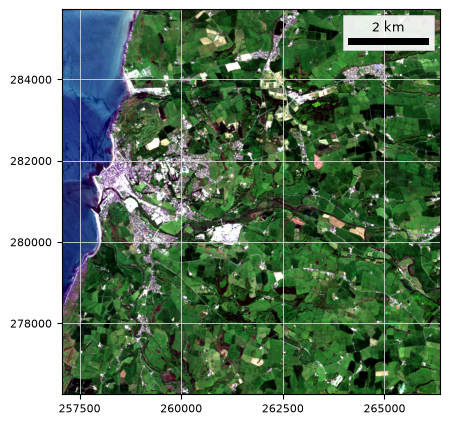

In [4]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    use_grid=True,  # Show a grid.
)

## Don't Show the Map Axes:

By default we show the map axes and the coordinates. However, you may not which to show these and they can be turned off as show below:

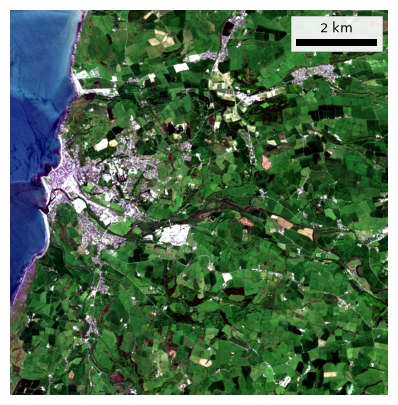

In [5]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    show_map_axis=False,  # Don't show the map axes.
)

## Don't show the scale bar

By default a scale bar is shown in the map in the top-right corner. This can be turned off:

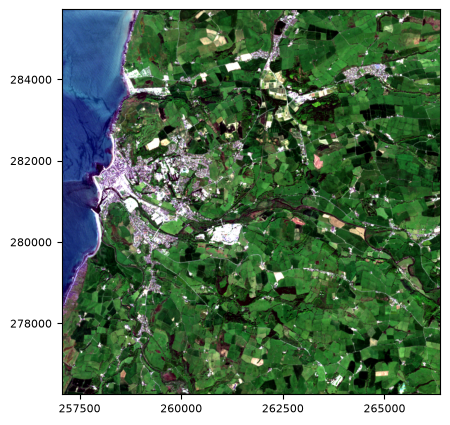

In [6]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    show_scale_bar=False,  # Don't show scale bar
)

## Move the scale bar location

You may not want the scale bar in the top-right corner and the `scale_bar_loc` option can be used to move it:

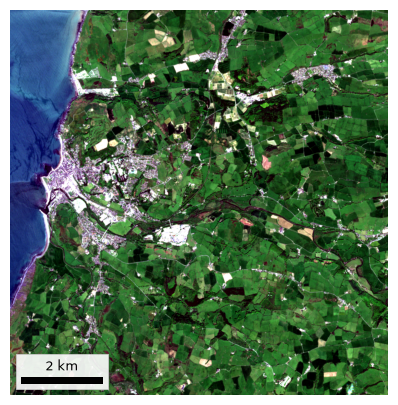

In [7]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    show_map_axis=False,
    scale_bar_loc="lower left",  # Specify scale bar location
)

## Add a North Arrow

A north arrow shows the reader which way is north. Set `show_north_arrow=True` to add one; `north_arrow_loc` places it (default `"upper left"`) and `north_arrow_style` chooses its look:

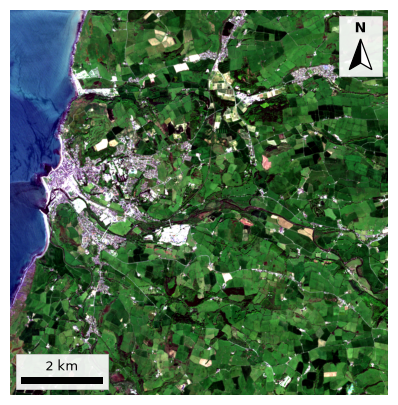

In [8]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    show_map_axis=False,
    scale_bar_loc="lower left",
    show_north_arrow=True,  # Add a north arrow
    north_arrow_loc="upper right",  # Specify north arrow location
)

### North arrow styles

A north arrow can also be added to any matplotlib axis (for example, one with a vector layer or several layers) with `rsgispy.mapping.elements.add_north_arrow`. It has four styles: `NORTH_ARROW_STYLE_TRIANGLE` (the default), `NORTH_ARROW_STYLE_ARROW`, `NORTH_ARROW_STYLE_COMPASS` and `NORTH_ARROW_STYLE_SIMPLE`. Its `size`, `colour`, `label` and background box (`frameon`, `box_colour`, `box_alpha`) can also be changed:

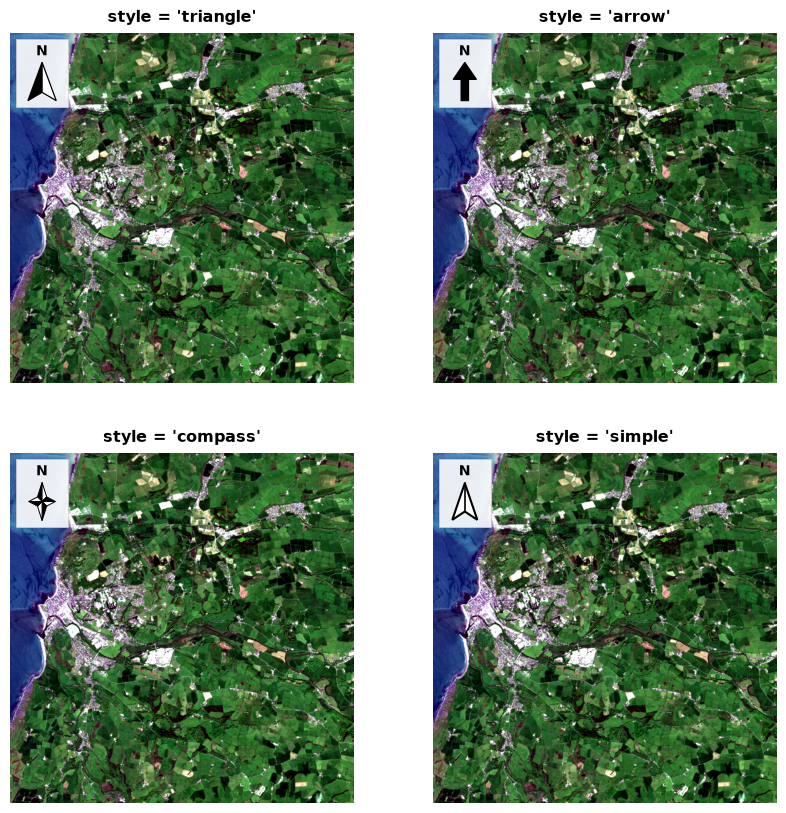

In [9]:
import rsgispy.mapping.elements

north_arrow_styles = [
    rsgispy.mapping.elements.NORTH_ARROW_STYLE_TRIANGLE,
    rsgispy.mapping.elements.NORTH_ARROW_STYLE_ARROW,
    rsgispy.mapping.elements.NORTH_ARROW_STYLE_COMPASS,
    rsgispy.mapping.elements.NORTH_ARROW_STYLE_SIMPLE,
]

fig, axs = plt.subplots(2, 2, figsize=(10, 10))
for ax, style in zip(axs.flatten(), north_arrow_styles):
    _ = rsgispy.mapping.raster.create_raster_img_map(
        ax,
        input_img,
        img_bands=[3, 2, 1],
        img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
        show_map_axis=False,
        show_scale_bar=False,
        title_str=f"style = '{style}'",
    )
    _ = rsgispy.mapping.elements.add_north_arrow(ax, loc="upper left", style=style, size=30)

**Note:** the north arrow points to the top of the map, which is *grid* north. In a projected coordinate system, grid north and true north differ slightly away from the projection's central meridian (by about 1.6° at Aberystwyth, which is about 2° west of the British National Grid's central meridian of 2° W). If you need to show the difference, the `rotation` option of `add_north_arrow` rotates the arrow (anticlockwise, in degrees).

## Rotate y-axis labels

You may want to rotate the y-axis labels to either 45 or 90 degrees to reduce the amount of white space to the side of the figure. This can be done with the following option:

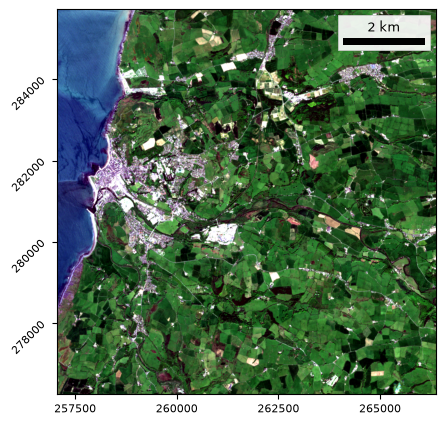

In [10]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
)
ax.tick_params(axis="y", labelrotation=45)

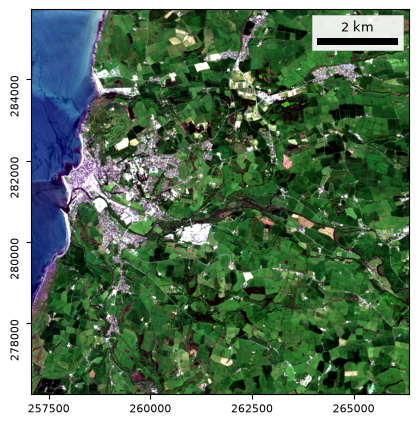

In [11]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[3, 2, 1],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
)
ax.tick_params(axis="y", labelrotation=90)

## Compare Different Stretches:

For imagery the most common approaches for stretching imagery are a standard deviation stretch and cululative stretch which are shown below:

The cumulative stretch uses the 2nd and 98th percentiles of each band as the minimum and maximum, while the standard deviation stretch uses the mean $\pm$ 2 standard deviations (the number of standard deviations can be changed with `stch_n_stdevs`).

To show maps side by side we could create the axes with `plt.subplots` and call `create_raster_img_map` for each axis (as the north arrow styles above do). `rsgispy.mapping.layout.create_map_panels` does this in one call: each panel is a dictionary (or a `rsgispy.mapping.layout.MapPanel`) giving its type (`"rgb"` for a stretched 1- or 3-band image, `"cmap"`, `"thematic"` or `"vector"`), the image, the bands, a title and any other options for the mapping function (`map_kw`). All the panels show the same extent (`bbox`, by default the extent of the first panel), one scale bar and north arrow are drawn on the first panel and the coordinate axes are hidden (`show_map_axis=True` shows them). The figure size is set from the extent and the number of panels (or give `figsize`), and the figure and an array of the axes are returned (`fig, axs`) so you can change the maps afterwards.

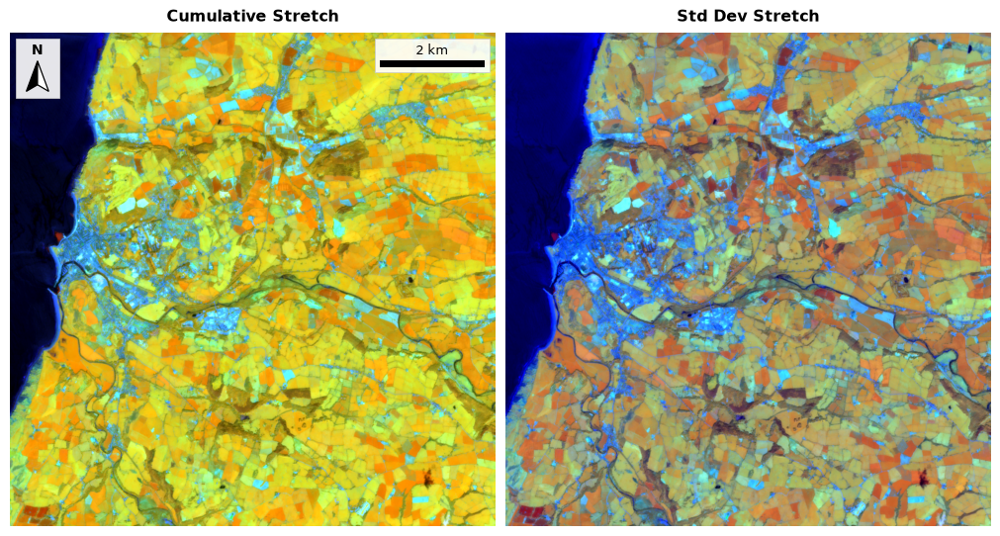

In [12]:
fig, axs = map_layout.create_map_panels(
    [
        {"panel_type": "rgb", "input_img": input_img, "bands": [8, 9, 3],
         "img_stch": rsgispy.IMG_STRETCH_CUMULATIVE, "title": "Cumulative Stretch"},
        {"panel_type": "rgb", "input_img": input_img, "bands": [8, 9, 3],
         "img_stch": rsgispy.IMG_STRETCH_STDEV, "title": "Std Dev Stretch"},
    ]
)

However, you might want manually specify the stretch min-max values or use a linear stretch which is shown below:

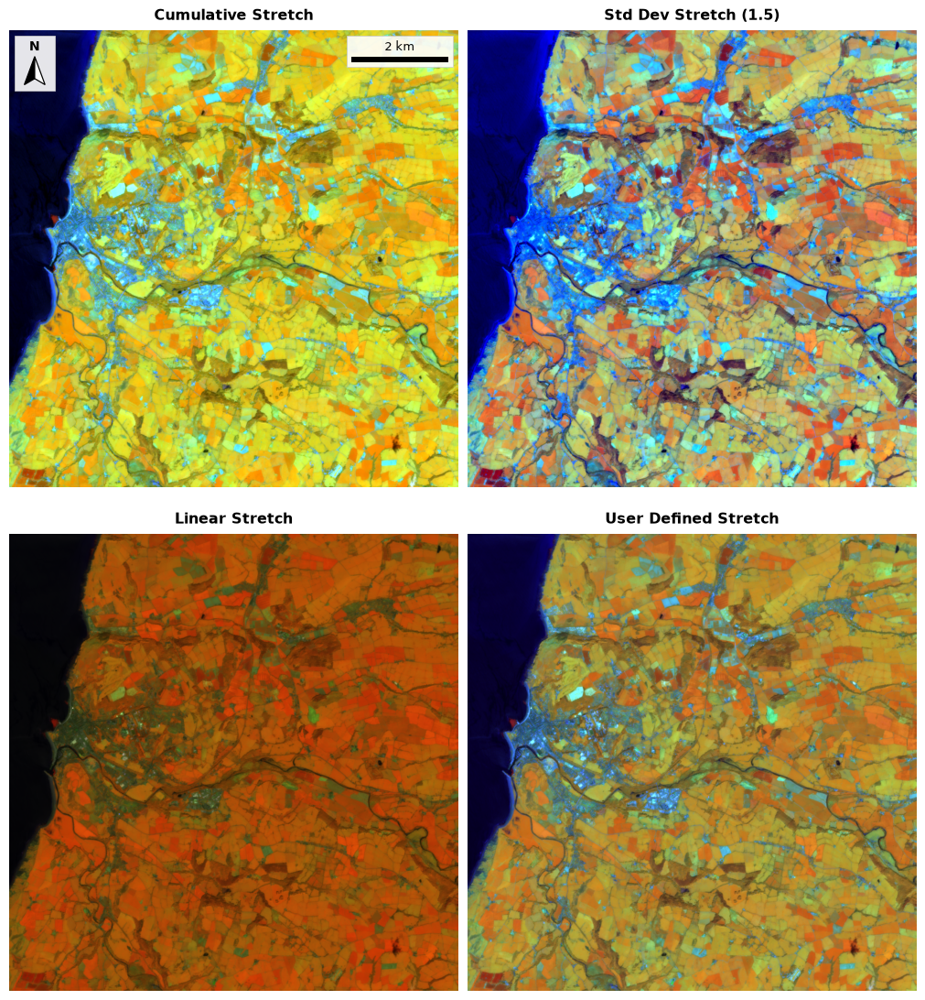

In [13]:
# specify the band min / max values for the stretch:
user_stch_vals = list()
user_stch_vals.append({"min": 10, "max": 800})
user_stch_vals.append({"min": 22, "max": 400})
user_stch_vals.append({"min": 1, "max": 200})

# The MapPanel class can be used instead of a dictionary. Options of
# create_raster_img_map which are not MapPanel fields (e.g., the number
# of standard deviations or the user stretch values) are given in map_kw.
fig, axs = map_layout.create_map_panels(
    [
        map_layout.MapPanel(
            "rgb", input_img, bands=[8, 9, 3],
            img_stch=rsgispy.IMG_STRETCH_CUMULATIVE, title="Cumulative Stretch",
        ),
        map_layout.MapPanel(
            "rgb", input_img, bands=[8, 9, 3],
            img_stch=rsgispy.IMG_STRETCH_STDEV,
            map_kw={"stch_n_stdevs": 1.5},  # specify the number of standard deviations
            title="Std Dev Stretch (1.5)",
        ),
        map_layout.MapPanel(
            "rgb", input_img, bands=[8, 9, 3],
            img_stch=rsgispy.IMG_STRETCH_LINEAR, title="Linear Stretch",
        ),
        map_layout.MapPanel(
            "rgb", input_img, bands=[8, 9, 3],
            img_stch=rsgispy.IMG_STRETCH_USER,
            map_kw={"stch_min_max_vals": user_stch_vals},  # user specified stretch min/max values
            title="User Defined Stretch",
        ),
    ],
    ncols=2,  # two panels per row
)

## Specifying Different Band Combinations

With multispectral data we need to specify which bands and what order the bands are used for visualisation. As you can see in the examples above this can be specified to the function:

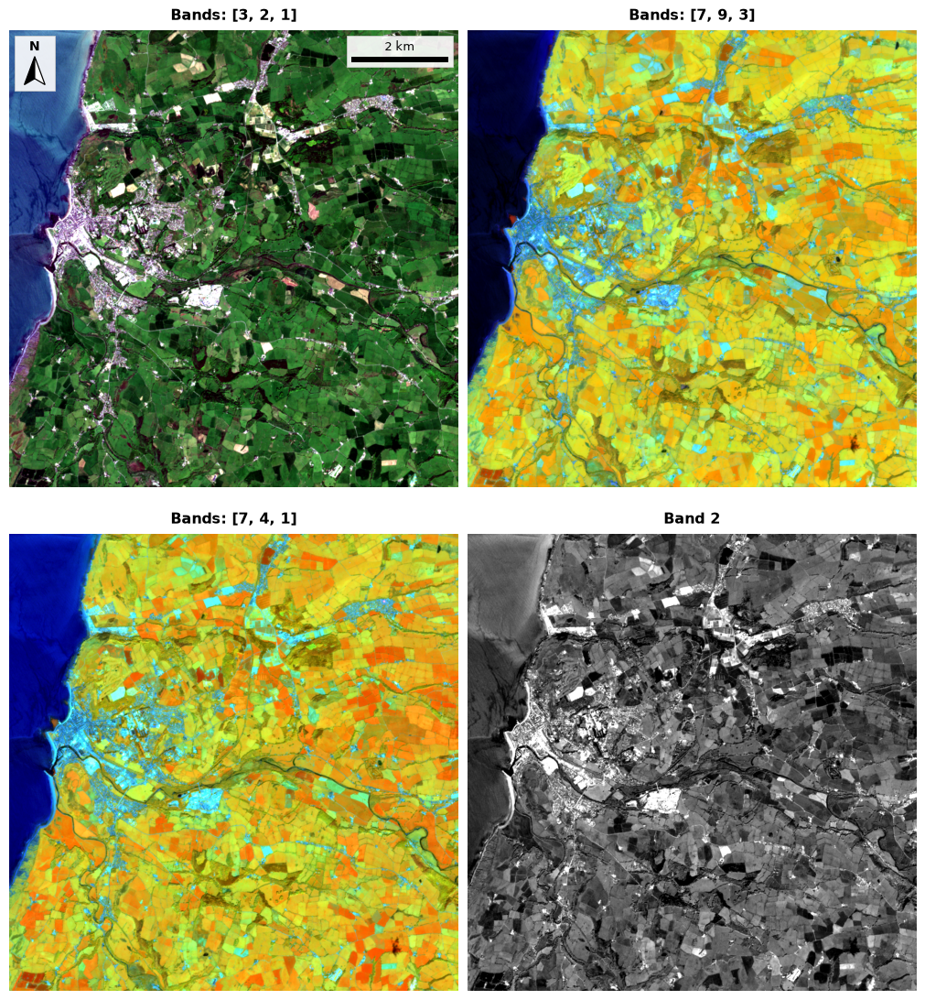

In [14]:
fig, axs = map_layout.create_map_panels(
    [
        # Bands 3 (red), 2 (green) and 1 (blue)
        {"panel_type": "rgb", "input_img": input_img, "bands": [3, 2, 1], "title": "Bands: [3, 2, 1]"},
        # NIR, SWIR1, Red
        {"panel_type": "rgb", "input_img": input_img, "bands": [7, 9, 3], "title": "Bands: [7, 9, 3]"},
        # NIR, RE1, Blue
        {"panel_type": "rgb", "input_img": input_img, "bands": [7, 4, 1], "title": "Bands: [7, 4, 1]"},
        # You can also specify just a single band: band 2 (green)
        {"panel_type": "rgb", "input_img": input_img, "bands": [2], "title": "Band 2"},
    ],
    ncols=2,
)

## Mapping a Subset

The examples above map the whole area of the input image but it is also used to just show a subset of the image - i.e., a zoomed in region. This is done by specifying a bounding box for the region of interest. 

The bounding box (bbox) is specified as `[xMin, xMax, yMin, yMax]` and should be in the same coordinate system as the input data. 

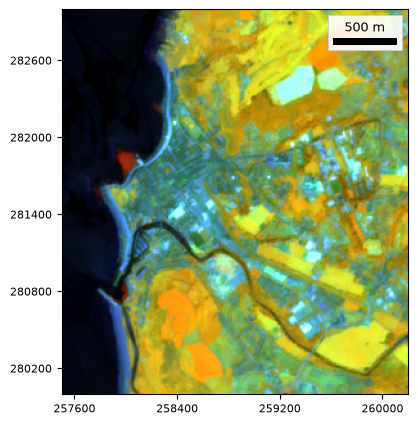

In [15]:
bbox = [257500, 260200, 280000, 283000]

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[8, 9, 3],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    bbox=bbox,  # specify the bbox defining the region of interest.
)

### Figure Shape

When defining the bounding box (bbox) you need to consider the shape you want the figure to be, clearly the x and y axis' of the map need to be equally scaled. Therefore, if the bbox is a rectangle the output figure will be also. 

For example:

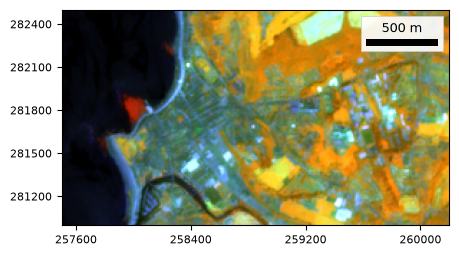

In [16]:
bbox = [257500, 260200, 281000, 282500]

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[8, 9, 3],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    bbox=bbox,  # specify the bbox defining the region of interest.
)

This can result in the figure having white space around it when saved as a image file, rather than shown within the notebook:

(See the outputted PNG: `outputs/rect_map_fig_exmpl_1.png`)

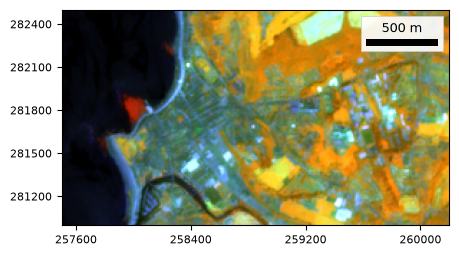

In [17]:
bbox = [257500, 260200, 281000, 282500]

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(5, 5))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[8, 9, 3],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    bbox=bbox,  # specify the bbox defining the region of interest.
)

plt.savefig(os.path.join(out_dir, "rect_map_fig_exmpl_1.png"))

To mitigate that white space the size and shape of the figure needs to be altered and rsgispy provides a function (`rsgispy.mapping.layout.calc_y_fig_size`) which can be used to help with this - note it might need slightly altering depending on the titles and length of the coordinates around the map.

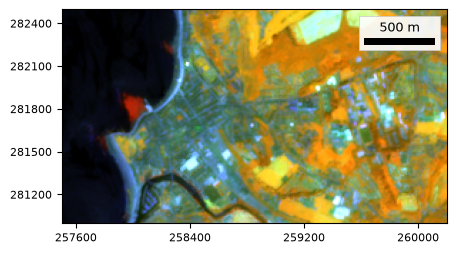

In [18]:
bbox = [257500, 260200, 281000, 282500]

fig_x_size = 5
fig_y_size = map_layout.calc_y_fig_size(bbox, fig_x_size)

# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(fig_x_size, fig_y_size))

_ = rsgispy.mapping.raster.create_raster_img_map(
    ax,
    input_img,
    img_bands=[8, 9, 3],
    img_stch=rsgispy.IMG_STRETCH_CUMULATIVE,
    bbox=bbox,  # specify the bbox defining the region of interest.
)

plt.savefig(os.path.join(out_dir, "rect_map_fig_exmpl_2.png"))

If you open `outputs/rect_map_fig_exmpl_2.png` you should find that it has less white space around it. 